In [4]:
# Customer Segmentation

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt

data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_cleaned+scaled.csv',encoding='ISO-8859-1')

In [2]:
customer_df = data.groupby('CustomerID').agg({
    # Dépenses et valeur transactionnelle
    'TotalSpent': 'sum',
    'NumTransactions': 'sum',
    'AvgTransactionValue': 'mean',
    'MaxTransactionValue': 'max',
    'TotalPrice': 'sum',
    'AvgPricePerItem': 'mean',
    'AvgUnitPriceSold': 'mean',
    'TotalQuantity': 'sum',
    'Quantity': 'sum',
    'AvgItemsPerTransaction': 'mean',
    'NumUniqueItemsBought': 'sum',
    'CustomerProductAffinity': 'mean',
    
    # RFM enrichi
    'RecencyDays': 'mean',
    'FrequencyPerMonth': 'mean',
    'MonetaryPerMonth': 'mean',
    'AvgDaysBetweenInvoices': 'mean',
    'TenureDays': 'mean',
    'TenureMonths': 'mean',
    'Recency_x_Frequency': 'mean',
    'Frequency_x_Monetary': 'mean',

    # Retour et satisfaction
    'ReturnRate': 'mean',
    'SentimentScore': 'mean',
    'AvgSentimentScore': 'mean',
    'IsDeluxe': 'mean',

    # Timing / saisonnalité
    'InvoiceMonth': lambda x: x.mode()[0],
    'InvoiceQuarter': lambda x: x.mode()[0],
    'InvoiceDayOfWeek': lambda x: x.mode()[0],
    'InvoiceHour': lambda x: x.mode()[0],
    'IsWeekend': 'mean',
    'IsHolidaySeason': 'mean',

    # Géographie / marché
    'CountryAvgSpend': 'mean',
    'CountryAvgSpendDeviation': 'mean',

    # Dates clés
    'FirstPurchase_Year': 'min',
    'FirstPurchase_Month': 'min',
    'FirstPurchase_Day': 'min',
    'FirstPurchase_Hour': 'min',
    'LastPurchase_Year': 'max',
    'LastPurchase_Month': 'max',
    'LastPurchase_Day': 'max',
    'LastPurchase_Hour': 'max',
    
}).reset_index()


In [3]:
customer_df

,CustomerID,TotalSpent,NumTransactions,AvgTransactionValue,MaxTransactionValue,TotalPrice,AvgPricePerItem,AvgUnitPriceSold,TotalQuantity,Quantity,...,CountryAvgSpend,CountryAvgSpendDeviation,FirstPurchase_Year,FirstPurchase_Month,FirstPurchase_Day,FirstPurchase_Hour,LastPurchase_Year,LastPurchase_Month,LastPurchase_Day,LastPurchase_Hour
0,0.000000,0.008780,0.008097,0.332581,0.403692,0.698533,0.349267,0.162275,0.401158,1.000,...,0.202429,0.365885,1.0,0.000000,0.566667,0.230769,1.0,0.000000,0.566667,0.285714
1,0.000168,7.162460,4.421053,0.380529,0.615385,72.074800,0.396015,0.340234,49.936931,113.325,...,0.400082,0.386876,0.0,1.000000,0.200000,0.538462,1.0,1.000000,0.200000,0.642857
2,0.000337,0.288458,0.376518,0.369183,0.461538,11.933567,0.384954,0.210008,7.975186,27.975,...,0.414486,0.374307,0.0,1.000000,0.500000,0.923077,1.0,0.727273,0.800000,0.500000
3,0.000505,1.194043,0.000000,0.370292,0.510769,28.180500,0.386034,0.456946,23.789909,39.050,...,0.311980,0.388099,1.0,0.909091,0.666667,0.153846,1.0,0.909091,0.666667,0.214286
4,0.000673,0.118846,0.000000,0.368406,0.393846,6.531333,0.384196,0.255733,4.077750,10.450,...,0.488357,0.364388,1.0,0.090909,0.033333,0.692308,1.0,0.090909,0.033333,0.714286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4367,0.998822,0.058378,0.000000,0.367350,0.388376,3.831667,0.383167,0.586726,2.084367,4.375,...,0.202429,0.398919,1.0,0.181818,0.200000,0.153846,1.0,0.181818,0.200000,0.214286
4368,0.998990,0.033732,0.000000,0.337934,0.364103,2.481400,0.354486,0.388854,1.472084,3.625,...,0.202429,0.370971,1.0,0.454545,0.366667,0.230769,1.0,0.454545,0.366667,0.285714
4369,0.999158,0.072951,0.105263,0.347011,0.386154,4.723367,0.363336,0.442152,2.694789,6.150,...,0.202429,0.379595,1.0,0.636364,0.133333,0.461538,1.0,1.000000,0.033333,0.357143
4370,0.999327,16.335173,43.785425,0.317331,0.378803,241.100433,0.334397,0.213849,160.312448,268.250,...,0.202429,0.351395,1.0,0.000000,0.166667,0.538462,1.0,1.000000,0.166667,0.428571


In [4]:
features = [
    # Dépenses et valeur transactionnelle
    'TotalSpent',
    'NumTransactions',
    'AvgTransactionValue',
    'MaxTransactionValue',
    'TotalQuantity',
    'AvgItemsPerTransaction',
    'NumUniqueItemsBought',
    'CustomerProductAffinity',
    
    # RFM enrichi
    'RecencyDays',
    'FrequencyPerMonth',
    'MonetaryPerMonth',
    'AvgDaysBetweenInvoices',
    'TenureDays',
    'TenureMonths',
    'Recency_x_Frequency',
    'Frequency_x_Monetary',
    
    # Retour et satisfaction
    'ReturnRate',
    'SentimentScore',
    'AvgSentimentScore',
    'IsDeluxe',
    
    # Timing / saisonnalité (si tu veux inclure les patterns temporels)
    'InvoiceMonth',
    'InvoiceQuarter',
    'InvoiceDayOfWeek',
    'InvoiceHour',
    'IsWeekend',
    'IsHolidaySeason',
    
    # Géographie / marché
    'CountryAvgSpendDeviation'
]


X = customer_df[features]

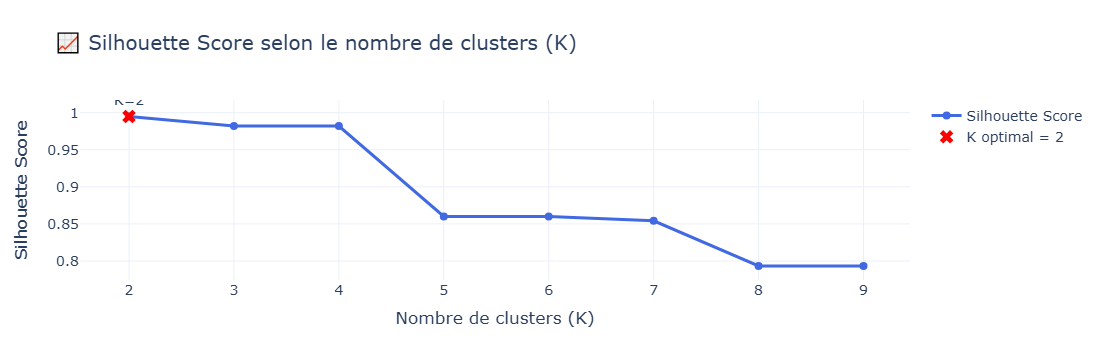

K optimal = 2 avec un score de silhouette de 0.995


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.graph_objects as go


scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)  
    score = silhouette_score(X, kmeans.labels_)
    scores.append(score)


optimal_k = K_range[np.argmax(scores)]
optimal_score = max(scores)

fig = go.Figure()


fig.add_trace(go.Scatter(
    x=list(K_range),
    y=scores,
    mode='lines+markers',
    name='Silhouette Score',
    line=dict(color='royalblue', width=3),
    marker=dict(size=8)
))


fig.add_trace(go.Scatter(
    x=[optimal_k],
    y=[optimal_score],
    mode='markers+text',
    name=f'K optimal = {optimal_k}',
    text=[f'K={optimal_k}'],
    textposition="top center",
    marker=dict(color='red', size=12, symbol='x')
))


fig.update_layout(
    title="📈 Silhouette Score selon le nombre de clusters (K)",
    xaxis_title="Nombre de clusters (K)",
    yaxis_title="Silhouette Score",
    template="plotly_white",
    font=dict(size=14),
    showlegend=True
)

fig.show()

print(f"K optimal = {optimal_k} avec un score de silhouette de {optimal_score:.3f}")


In [6]:
optimal_k = 2  
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
customer_df['Cluster'] = kmeans.fit_predict(X)


In [7]:
cluster_profile = customer_df.groupby('Cluster')[features].mean().round(2)
print(cluster_profile)


         TotalSpent  NumTransactions  AvgTransactionValue  \
Cluster                                                     
0              4.59             4.79                 0.37   
1           3204.22          5079.05                 0.34   

         MaxTransactionValue  TotalQuantity  AvgItemsPerTransaction  \
Cluster                                                               
0                       0.49          23.22                    0.56   
1                       0.90        1587.23                    0.47   

         NumUniqueItemsBought  CustomerProductAffinity  RecencyDays  \
Cluster                                                               
0                        8.98                     0.19         0.24   
1                     5363.19                     0.01         0.00   

         FrequencyPerMonth  ...  SentimentScore  AvgSentimentScore  IsDeluxe  \
Cluster                     ...                                                
0                     0.0

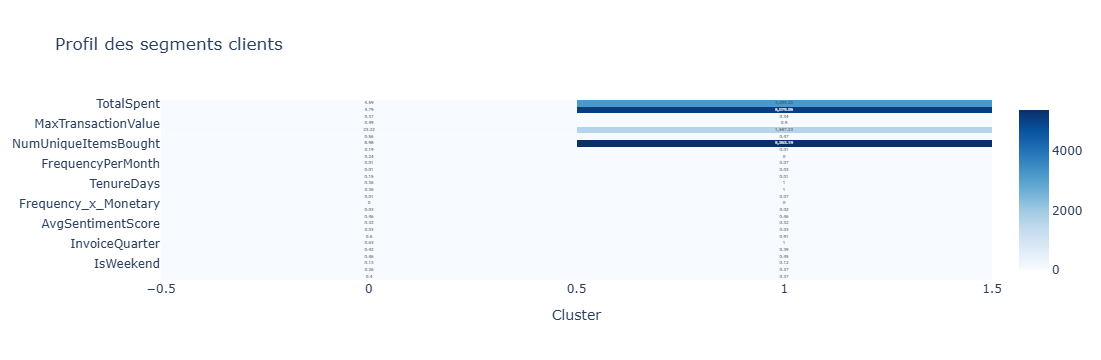

In [8]:
import plotly.express as px

fig = px.imshow(cluster_profile.T, text_auto=True, 
                color_continuous_scale='Blues',
                title="Profil des segments clients")
fig.show()


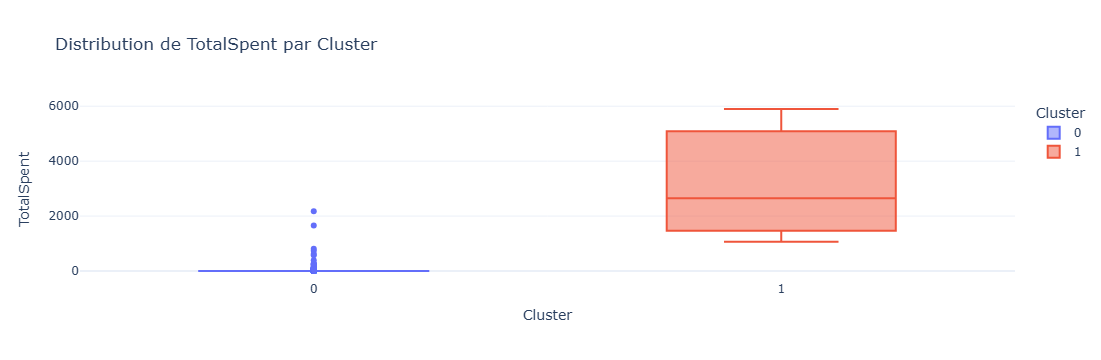

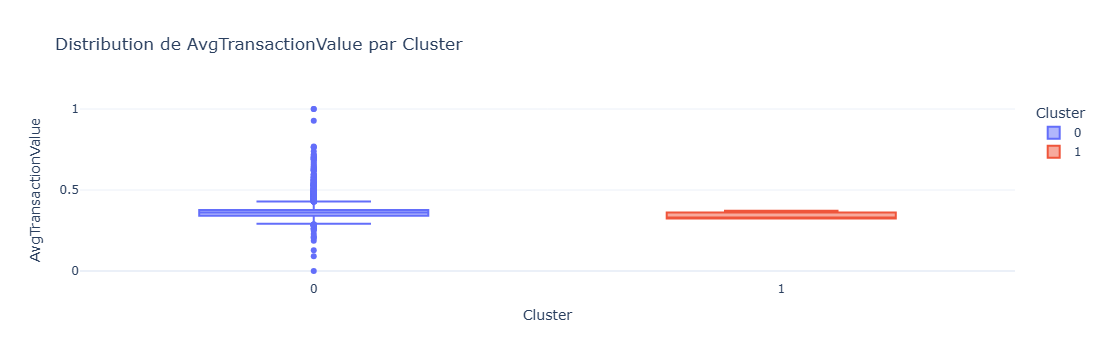

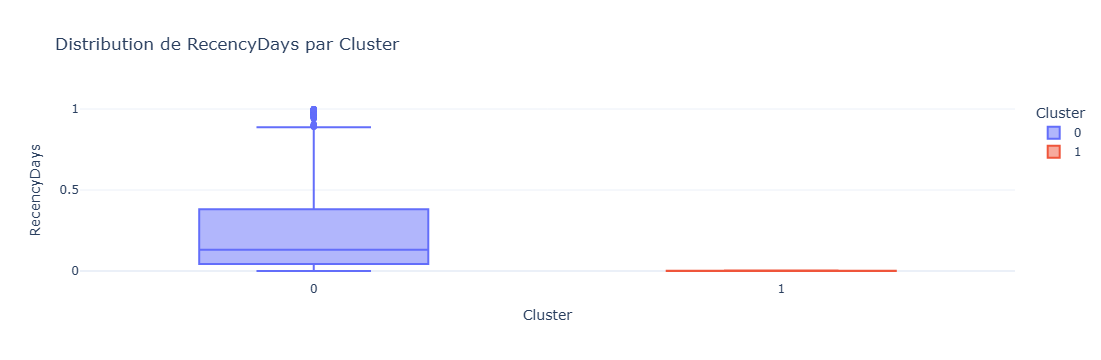

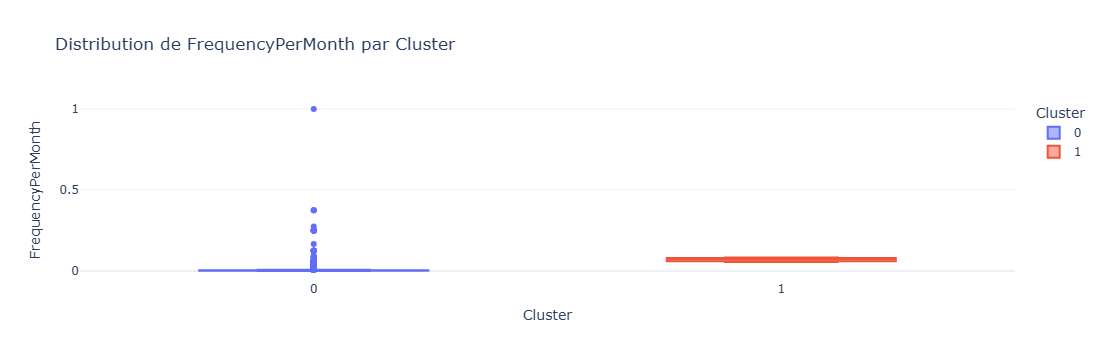

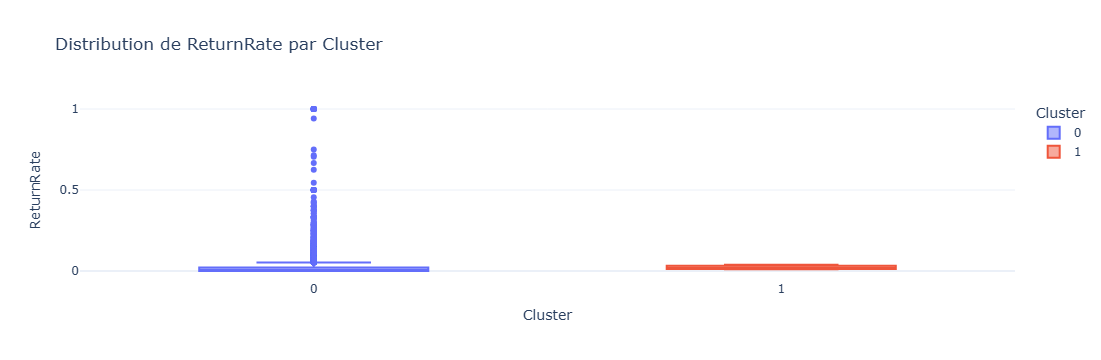

In [9]:
import plotly.express as px

for col in ['TotalSpent', 'AvgTransactionValue', 'RecencyDays', 'FrequencyPerMonth', 'ReturnRate']:
    fig = px.box(customer_df, x='Cluster', y=col, color='Cluster',
                 title=f'Distribution de {col} par Cluster',
                 template='plotly_white')
    fig.show()


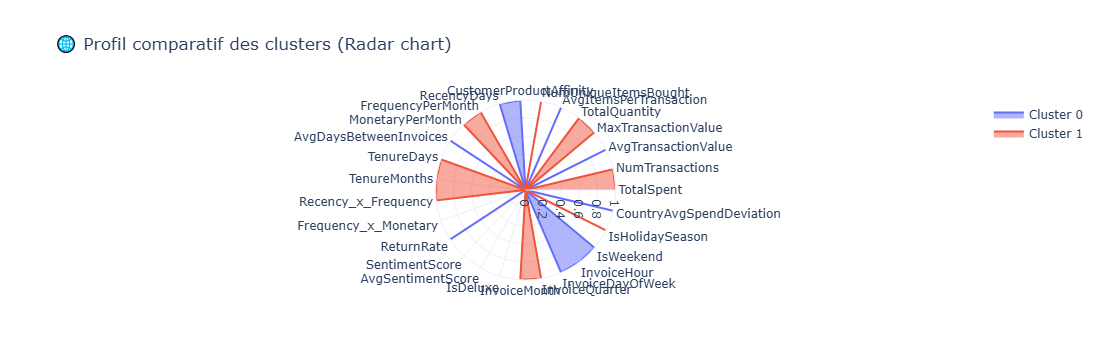

In [10]:
from sklearn.preprocessing import MinMaxScaler
import plotly.graph_objects as go

scaler = MinMaxScaler()
cluster_norm = pd.DataFrame(
    scaler.fit_transform(cluster_profile),
    columns=cluster_profile.columns,
    index=cluster_profile.index
)

# radar chart
categories = cluster_norm.columns
fig = go.Figure()

for i in cluster_norm.index:
    fig.add_trace(go.Scatterpolar(
        r=cluster_norm.loc[i].values,
        theta=categories,
        fill='toself',
        name=f'Cluster {i}'
    ))

fig.update_layout(
    polar=dict(radialaxis=dict(visible=True)),
    title="🌐 Profil comparatif des clusters (Radar chart)",
    template="plotly_white"
)
fig.show()


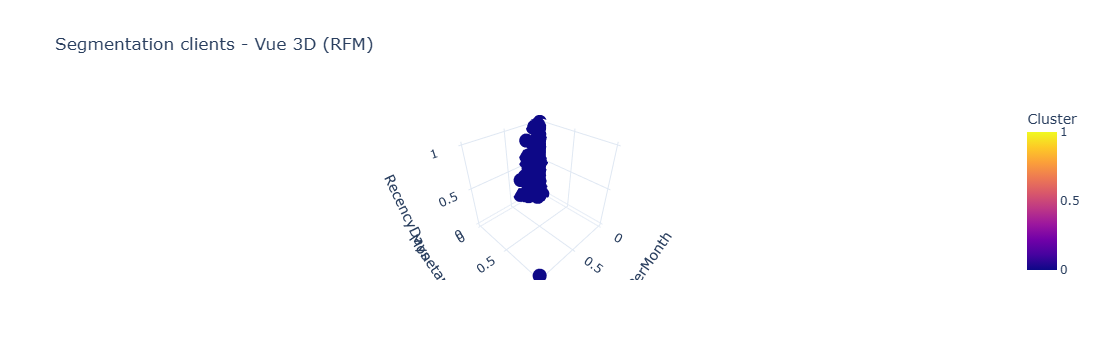

In [11]:
fig = px.scatter_3d(customer_df, 
                    x='FrequencyPerMonth', 
                    y='MonetaryPerMonth', 
                    z='RecencyDays',
                    color='Cluster',
                    title='Segmentation clients - Vue 3D (RFM)',
                    template='plotly_white')
fig.show()


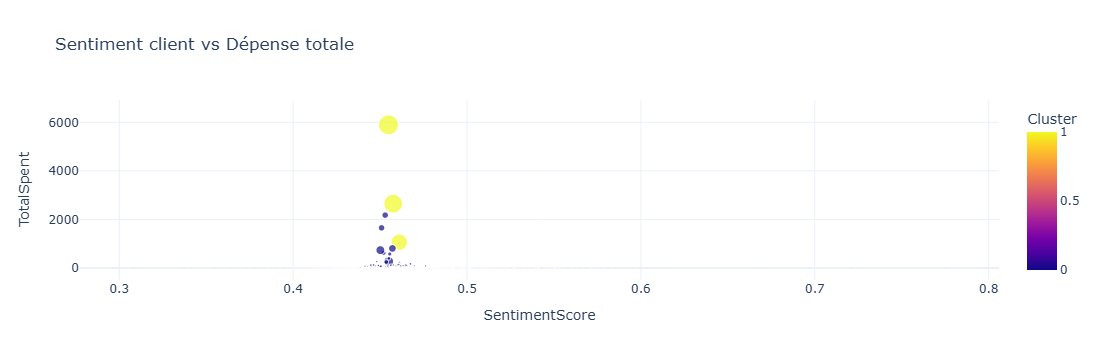

In [12]:
fig = px.scatter(customer_df, 
                 x='SentimentScore', 
                 y='TotalSpent', 
                 color='Cluster',
                 size='NumTransactions',
                 hover_data=['AvgTransactionValue'],
                 title='Sentiment client vs Dépense totale',
                 template='plotly_white')
fig.show()


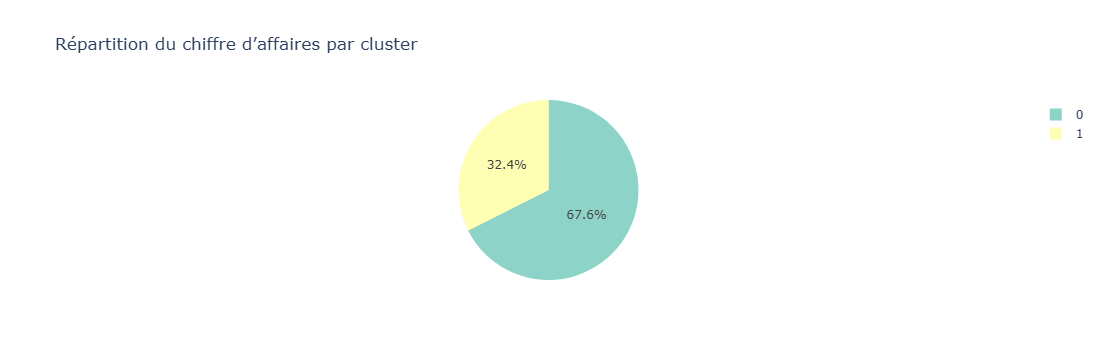

In [13]:
cluster_sales = customer_df.groupby('Cluster')['TotalSpent'].sum().reset_index()
fig = px.pie(cluster_sales, values='TotalSpent', names='Cluster', 
             title='Répartition du chiffre d’affaires par cluster',
             color_discrete_sequence=px.colors.qualitative.Set3)
fig.show()


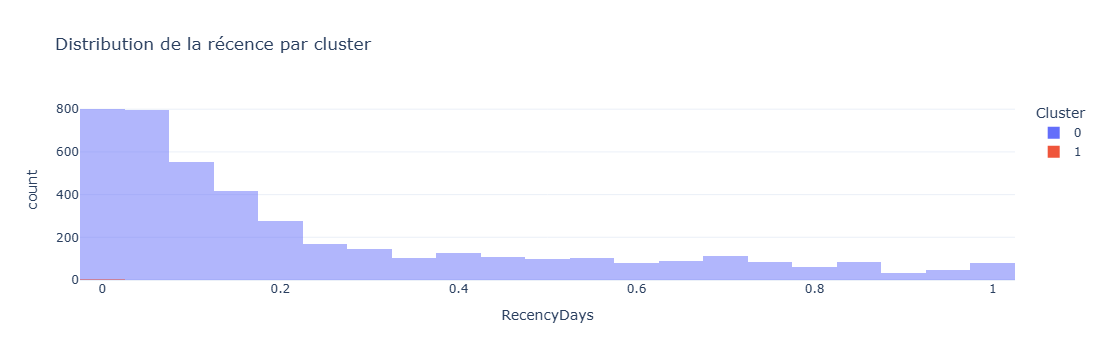

In [14]:
fig = px.histogram(customer_df, x='RecencyDays', color='Cluster',
                   nbins=30, barmode='overlay',
                   title='Distribution de la récence par cluster',
                   template='plotly_white')
fig.show()


In [15]:
summary = cluster_profile.copy()
summary['Insight'] = summary.apply(lambda row:
    "Premium clients (High spend, frequent)" if row['TotalSpent'] > summary['TotalSpent'].mean() and row['FrequencyPerMonth'] > summary['FrequencyPerMonth'].mean()
    else "Occasional buyers" if row['FrequencyPerMonth'] < summary['FrequencyPerMonth'].mean()
    else "Inactive customers" if row['RecencyDays'] > summary['RecencyDays'].mean()
    else "Loyal mid-spenders", axis=1)

summary[['Insight']]


,Insight
Cluster,
0,Occasional buyers
1,"Premium clients (High spend, frequent)"


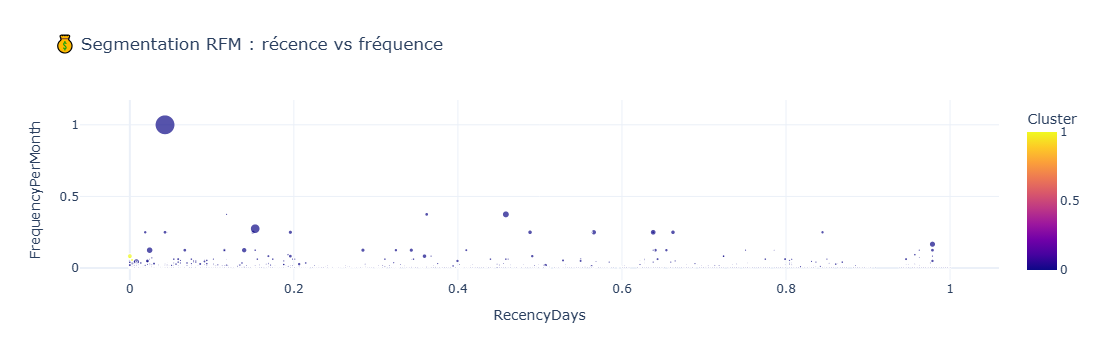

In [16]:
fig = px.scatter(customer_df, 
                 x='RecencyDays', 
                 y='FrequencyPerMonth', 
                 color='Cluster',
                 size='MonetaryPerMonth',
                 hover_data=['TotalSpent'],
                 title='💰 Segmentation RFM : récence vs fréquence',
                 template='plotly_white')
fig.show()


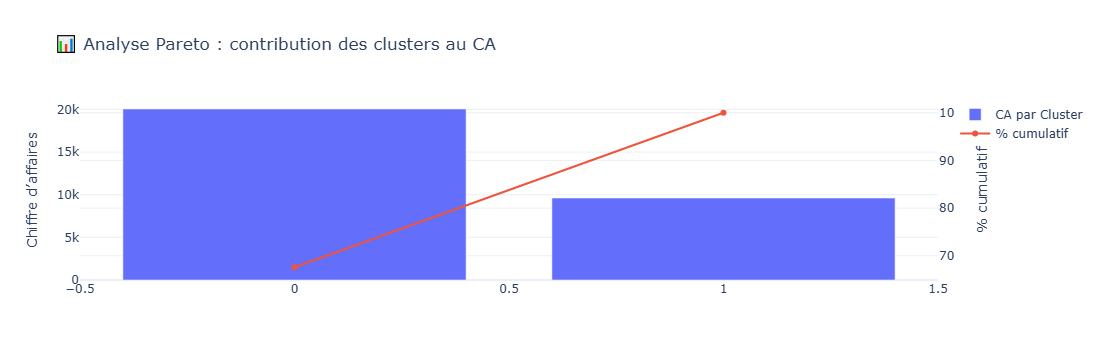

In [17]:
pareto = cluster_sales.sort_values('TotalSpent', ascending=False)
pareto['Cumulative%'] = pareto['TotalSpent'].cumsum() / pareto['TotalSpent'].sum() * 100

fig = go.Figure()
fig.add_trace(go.Bar(x=pareto['Cluster'], y=pareto['TotalSpent'], name='CA par Cluster'))
fig.add_trace(go.Scatter(x=pareto['Cluster'], y=pareto['Cumulative%'], 
                         mode='lines+markers', name='% cumulatif', yaxis='y2'))

fig.update_layout(
    title="📊 Analyse Pareto : contribution des clusters au CA",
    yaxis=dict(title='Chiffre d’affaires'),
    yaxis2=dict(title='% cumulatif', overlaying='y', side='right'),
    template='plotly_white'
)
fig.show()


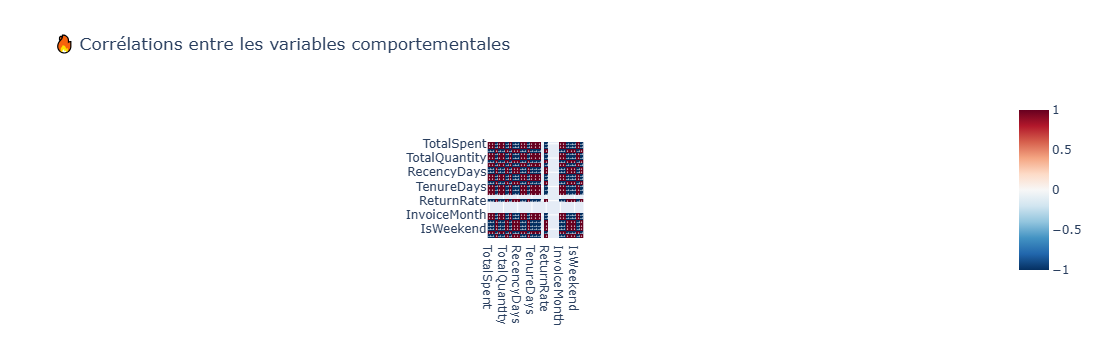

In [18]:
corr = cluster_profile.corr()
fig = px.imshow(corr, text_auto=True, color_continuous_scale='RdBu_r',
                title="🔥 Corrélations entre les variables comportementales")
fig.show()


# 🎯 Analyse des Segments Clients & Recommandations Marketing

Après la segmentation, nous avons identifié **2 clusters principaux** :

---

## 🔥 Cluster 0 : Clients Premium / Deluxe
**Profil :**
- 💰 Dépenses totales élevées (`TotalSpent`)
- 📈 Fréquence d'achat importante (`FrequencyPerMonth`)
- 🛒 Transactions plus chères (`AvgTransactionValue`)
- ✨ Forte proportion de clients **Deluxe**
- 😊 Sentiment global positif

**Insights :**
- Segment **source principale de profit**
- Clients fidèles et à forte valeur (high CLV)
- Engagement élevé, sensibles aux offres premium

**💡 Recommandations Marketing :**
1. 🎁 Programmes de fidélité premium : cartes VIP, points supplémentaires, avant-premières  
2. 🛍️ Offres personnalisées : promotions sur produits exclusifs  
3. 📣 Communication ciblée : email / SMS sur nouveautés deluxe  
4. 🔄 Upsell & Cross-sell : bundles ou produits complémentaires à forte valeur  

---

## 🌱 Cluster 1 : Clients Occasionnels / Standard
**Profil :**
- 💸 Dépenses plus faibles
- 📉 Fréquence d'achat plus basse
- 🛒 Transactions plus petites
- ✨ Moins de clients Deluxe
- 😐 Sentiment variable, engagement moyen

**Insights :**
- Segment **à potentiel de croissance** via réactivation
- Clients sensibles au prix et moins engagés

**💡 Recommandations Marketing :**
1. ⏰ Campagnes de réactivation : offres limitées dans le temps  
2. 🏆 Incitations à la fidélité : récompenses pour fréquence d'achat  
3. 🎯 Segmentation par intérêts : promotions ciblées selon historique  
4. 📧 Communication éducative : emails mettant en avant avantages produits et marque  

---

## ✅ Conclusion
- **Cluster 0** : clients rentables → fidéliser, upsell, offres premium  
- **Cluster 1** : clients à potentiel → réactiver, engager et convertir  

> Cette segmentation permet de **maximiser le chiffre d’affaires**, **fidéliser les clients clés** et **stimuler la croissance des segments moins actifs**.
